# Modeling artificial networks and comparing them with real networks

**Steps (from the assignment):**
1. Feature table for 3 real datasets (small / medium / large) from SNAP — the link given on the last slide of `02_Graph_Theory_2`.
2. Degree distribution and clustering-coefficient distribution for each dataset.
3. 5 Erdős–Rényi, 5 Watts–Strogatz and 5 Barabási–Albert graphs with N equal to the smallest dataset and L as close as possible to it; feature tables (+ std of edge counts) and distribution plots.
4. Analysis (written in the report).

**Definitions used (from the course slides):**
* ⟨k⟩ = 2L/N for undirected graphs, ⟨k⟩ = L/N for directed graphs (same convention as the table on slide 34 of `03_NetworksModels`).
* Distance = number of edges on the shortest path; infinite for disconnected pairs (slide 61, `02_Graph_Theory`). Therefore diameter, radius and ⟨d⟩ are computed on the **giant component** (slide 68); for the directed graph on the **largest strongly connected component** (slide 70), following edge directions.
* Local clustering coefficient Cᵢ = 2eᵢ/(kᵢ(kᵢ−1)), with Cᵢ = 0 for kᵢ < 2; ⟨C⟩ = mean of Cᵢ over all nodes (example on slide 81, `02_Graph_Theory`). For the directed graph, C is computed on its undirected version.

In [1]:
# CELL 1 - Install igraph (fast C-based BFS). Other libraries are pre-installed in Colab.
%pip install -q python-igraph

Note: you may need to restart the kernel to use updated packages.


In [2]:
# CELL 2 - Imports, display options and the data/results folders.
import os, math, time, urllib.request
import numpy as np
import pandas as pd
import networkx as nx
import igraph as ig
import matplotlib.pyplot as plt
from scipy.stats import poisson

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
DATA_DIR, OUT_DIR = "data", "results"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)
print("networkx", nx.__version__, "| igraph", ig.__version__)

networkx 3.7 | igraph 1.0.0


## 0. Helper functions
* Graphs are loaded with **networkx**; the heavy distance computations (BFS from many sources) use **igraph**, whose BFS is written in C and is ~50–100× faster. Both give identical results.
* For graphs whose giant component has ≤ 40,000 nodes everything is **exact** (BFS from every node).
* For the large graph (DBLP, 317k nodes) exact all-pairs BFS would take hours, so:
  * diameter and radius are still **exact**, using the bounding-eccentricities algorithm (Takes & Kosters, 2011 — the same algorithm behind `nx.diameter(G, usebounds=True)`), which needs only a few BFS runs;
  * ⟨d⟩ is **estimated** from BFS runs from 1000 random source nodes (reported with its standard error).

In [3]:
# CELL 3 - Helper functions: networkx->igraph conversion, exact diameter/radius (bounding
# eccentricities), sampled average path length, local clustering, and graph_properties(),
# which builds one row of the feature table (<k>, diameter, radius, <d>, <C>, lnN, lnN/ln<k>).
def nx_to_ig(G):
    # Convert a networkx graph to igraph (nodes relabelled 0..n-1).
    nodes = list(G.nodes())
    idx = {v: i for i, v in enumerate(nodes)}
    return ig.Graph(n=len(nodes), edges=[(idx[u], idx[v]) for u, v in G.edges()],
                    directed=G.is_directed())


def bounding_diameter_radius(g):
    # Exact diameter and radius of a connected undirected igraph graph (Takes & Kosters 2011).
    # For every BFS from v with eccentricity e: max(d(v,w), e-d(v,w)) <= ecc(w) <= e + d(v,w).
    n = g.vcount()
    deg = np.array(g.degree())
    lo, hi = np.zeros(n, dtype=np.int64), np.full(n, n, dtype=np.int64)
    cand = np.ones(n, dtype=bool)
    diam_lo, rad_hi = 0, n
    pick_high, n_bfs = True, 0
    while cand.any():
        if diam_lo == hi.max() and rad_hi == lo.min():
            break
        idx = np.flatnonzero(cand)
        if pick_high:   # largest upper bound (ties -> highest degree)
            v = idx[np.argmax(hi[idx] * (deg.max() + 1) + deg[idx])]
        else:           # smallest lower bound (ties -> highest degree)
            v = idx[np.argmin(lo[idx] * (deg.max() + 1) - deg[idx])]
        pick_high = not pick_high
        d = np.asarray(g.distances(source=[int(v)])[0], dtype=np.int64)
        n_bfs += 1
        e = int(d.max())
        lo = np.maximum(lo, np.maximum(d, e - d))
        hi = np.minimum(hi, e + d)
        lo[v] = hi[v] = e
        diam_lo, rad_hi = max(diam_lo, e), min(rad_hi, e)
        # a node can no longer change the diameter nor the radius -> drop it
        cand &= ~((hi <= diam_lo) & (lo >= rad_hi))
        cand[v] = False
    return diam_lo, rad_hi, n_bfs


def sampled_aspl(g, n_sources=1000, seed=0, chunk=50):
    # Average shortest path length estimated from BFS runs from random sources.
    rng = np.random.default_rng(seed)
    src = rng.choice(g.vcount(), size=min(n_sources, g.vcount()), replace=False)
    per_source = []
    for i in range(0, len(src), chunk):
        D = np.asarray(g.distances(source=src[i:i + chunk].tolist()), dtype=float)
        for row in D:
            row = row[np.isfinite(row) & (row > 0)]
            per_source.append(row.mean())
    per_source = np.array(per_source)
    return per_source.mean(), per_source.std(ddof=1) / math.sqrt(len(per_source))


def local_clustering(G):
    # C_i for every node (C_i = 0 if k_i < 2); directed graphs -> undirected version.
    H = G.to_undirected() if G.is_directed() else G
    g = nx_to_ig(H)
    g.simplify()
    return np.array(g.transitivity_local_undirected(mode="zero"))


def graph_properties(G, name, exact_limit=40_000, n_sources=1000, seed=0):
    # One row of the feature table + the arrays needed for the plots.
    t0 = time.time()
    directed = G.is_directed()
    N, L = G.number_of_nodes(), G.number_of_edges()
    k_avg = L / N if directed else 2 * L / N
    comps = nx.strongly_connected_components(G) if directed else nx.connected_components(G)
    gc_nodes = max(comps, key=len)
    g = nx_to_ig(G.subgraph(gc_nodes))
    n_gc = g.vcount()
    if n_gc <= exact_limit:
        ecc = np.array(g.eccentricity(mode="out"))
        diam, rad = int(ecc.max()), int(ecc.min())
        aspl, aspl_se = g.average_path_length(directed=directed), 0.0
        method = "exact"
    else:
        if directed:
            raise ValueError("bounding algorithm implemented for undirected graphs only")
        diam, rad, n_bfs = bounding_diameter_radius(g)
        aspl, aspl_se = sampled_aspl(g, n_sources, seed)
        method = f"diam/radius exact ({n_bfs} BFS); <d> from {n_sources} random sources"
    C = local_clustering(G)
    row = {
        "Dataset": name, "N (nodes)": N, "L (edges)": L, "<k>": k_avg,
        "Diameter": diam, "Radius": rad, "<d>": aspl,
        "Type": "Directed" if directed else "Undirected", "<C>": C.mean(),
        "lnN": math.log(N), "lnN/ln<k>": math.log(N) / math.log(k_avg),
        "Giant comp. nodes": n_gc, "Giant comp. %": 100 * n_gc / N,
    }
    extra = {"C": C, "method": method, "aspl_se": aspl_se}
    if directed:
        extra["k_in"] = np.array([d for _, d in G.in_degree()])
        extra["k_out"] = np.array([d for _, d in G.out_degree()])
    else:
        extra["k"] = np.array([d for _, d in G.degree()])
    print(f"{name:<12} N={N:,} L={L:,}  [{method}]  {time.time() - t0:.1f}s")
    return row, extra

## 1. Real datasets (SNAP)
| size | dataset | what it is |
|---|---|---|
| small | `ca-GrQc` | co-authorship network, arXiv General Relativity (undirected) |
| medium | `cit-HepTh` | citation network, arXiv HEP-Theory (directed) |
| large | `com-DBLP` | co-authorship network, DBLP computer science (undirected) |

Self-loops are removed; duplicate edges collapse automatically (simple graphs).
`ca-GrQc` stores every undirected edge in both directions (28,980 lines), i.e. 14,496 undirected edges as on its SNAP page; 12 of them are self-loops, so the simple graph has **14,484** edges.
`cit-HepTh` has 352,807 edges on SNAP, 39 of which are self-loops (a paper citing itself), so the simple graph has **352,768** edges.

In [4]:
# CELL 4 - Download the 3 SNAP datasets (small / medium / large) and load them as graphs.
# Self-loops are removed.
DATASETS = {   # name: (url, directed)
    "ca-GrQc":   ("https://snap.stanford.edu/data/ca-GrQc.txt.gz", False),
    "cit-HepTh": ("https://snap.stanford.edu/data/cit-HepTh.txt.gz", True),
    "com-DBLP":  ("https://snap.stanford.edu/data/bigdata/communities/com-dblp.ungraph.txt.gz", False),
}

def load_snap(name, url, directed):
    path = os.path.join(DATA_DIR, url.split("/")[-1])
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, path)
    G = nx.read_edgelist(path, comments="#", nodetype=int,
                         create_using=nx.DiGraph() if directed else nx.Graph())
    G.remove_edges_from(list(nx.selfloop_edges(G)))
    return G

graphs = {name: load_snap(name, url, d) for name, (url, d) in DATASETS.items()}
for name, G in graphs.items():
    print(f"{name:<10} N={G.number_of_nodes():>8,}  L={G.number_of_edges():>10,}  directed={G.is_directed()}")

ca-GrQc    N=   5,242  L=    14,484  directed=False
cit-HepTh  N=  27,770  L=   352,768  directed=True
com-DBLP   N= 317,080  L= 1,049,866  directed=False


In [5]:
# CELL 5 - Task 1: feature table of the 3 real networks (also saved as CSV).
# Takes about 1 minute (mostly DBLP).
real_rows, real_extra = [], {}
for name, G in graphs.items():
    row, extra = graph_properties(G, name)
    real_rows.append(row)
    real_extra[name] = extra

real_table = pd.DataFrame(real_rows)
real_table.to_csv(f"{OUT_DIR}/table1_real_networks.csv", index=False)
for name, e in real_extra.items():
    print(f"{name}: {e['method']}" + (f" (standard error of <d> = {e['aspl_se']:.4f})" if e['aspl_se'] else ""))
real_table.round(4)

ca-GrQc      N=5,242 L=14,484  [exact]  1.2s


cit-HepTh    N=27,770 L=352,768  [exact]  8.7s


com-DBLP     N=317,080 L=1,049,866  [diam/radius exact (9 BFS); <d> from 1000 random sources]  60.7s
ca-GrQc: exact
cit-HepTh: exact
com-DBLP: diam/radius exact (9 BFS); <d> from 1000 random sources (standard error of <d> = 0.0299)


,Dataset,N (nodes),L (edges),<k>,Diameter,Radius,<d>,Type,<C>,lnN,lnN/ln<k>,Giant comp. nodes,Giant comp. %
0,ca-GrQc,5242,14484,5.5261,17,9,6.0494,Undirected,0.5296,8.5645,5.0100,4158,79.3209
1,cit-HepTh,27770,352768,12.7032,35,13,9.8008,Directed,0.3120,10.2317,4.0253,7464,26.8779
2,com-DBLP,317080,1049866,6.6221,23,12,6.8288,Undirected,0.6324,12.6669,6.7006,317080,100.0000


## 2. Degree distribution and clustering-coefficient distribution of the real networks
* **Degree distribution:** pₖ = Nₖ/N (slide 19, `02_Graph_Theory`) on log–log axes; nodes with k = 0 cannot be drawn on a log axis.
  The green curve is the Poisson prediction of a random network with the same ⟨k⟩ (as on slide 18, `03_NetworksModels`).
  For the directed network the in-degree and out-degree distributions are drawn separately.
* **Clustering distribution:** fraction of nodes whose Cᵢ falls in each of 20 bins in [0, 1] (log y-axis).

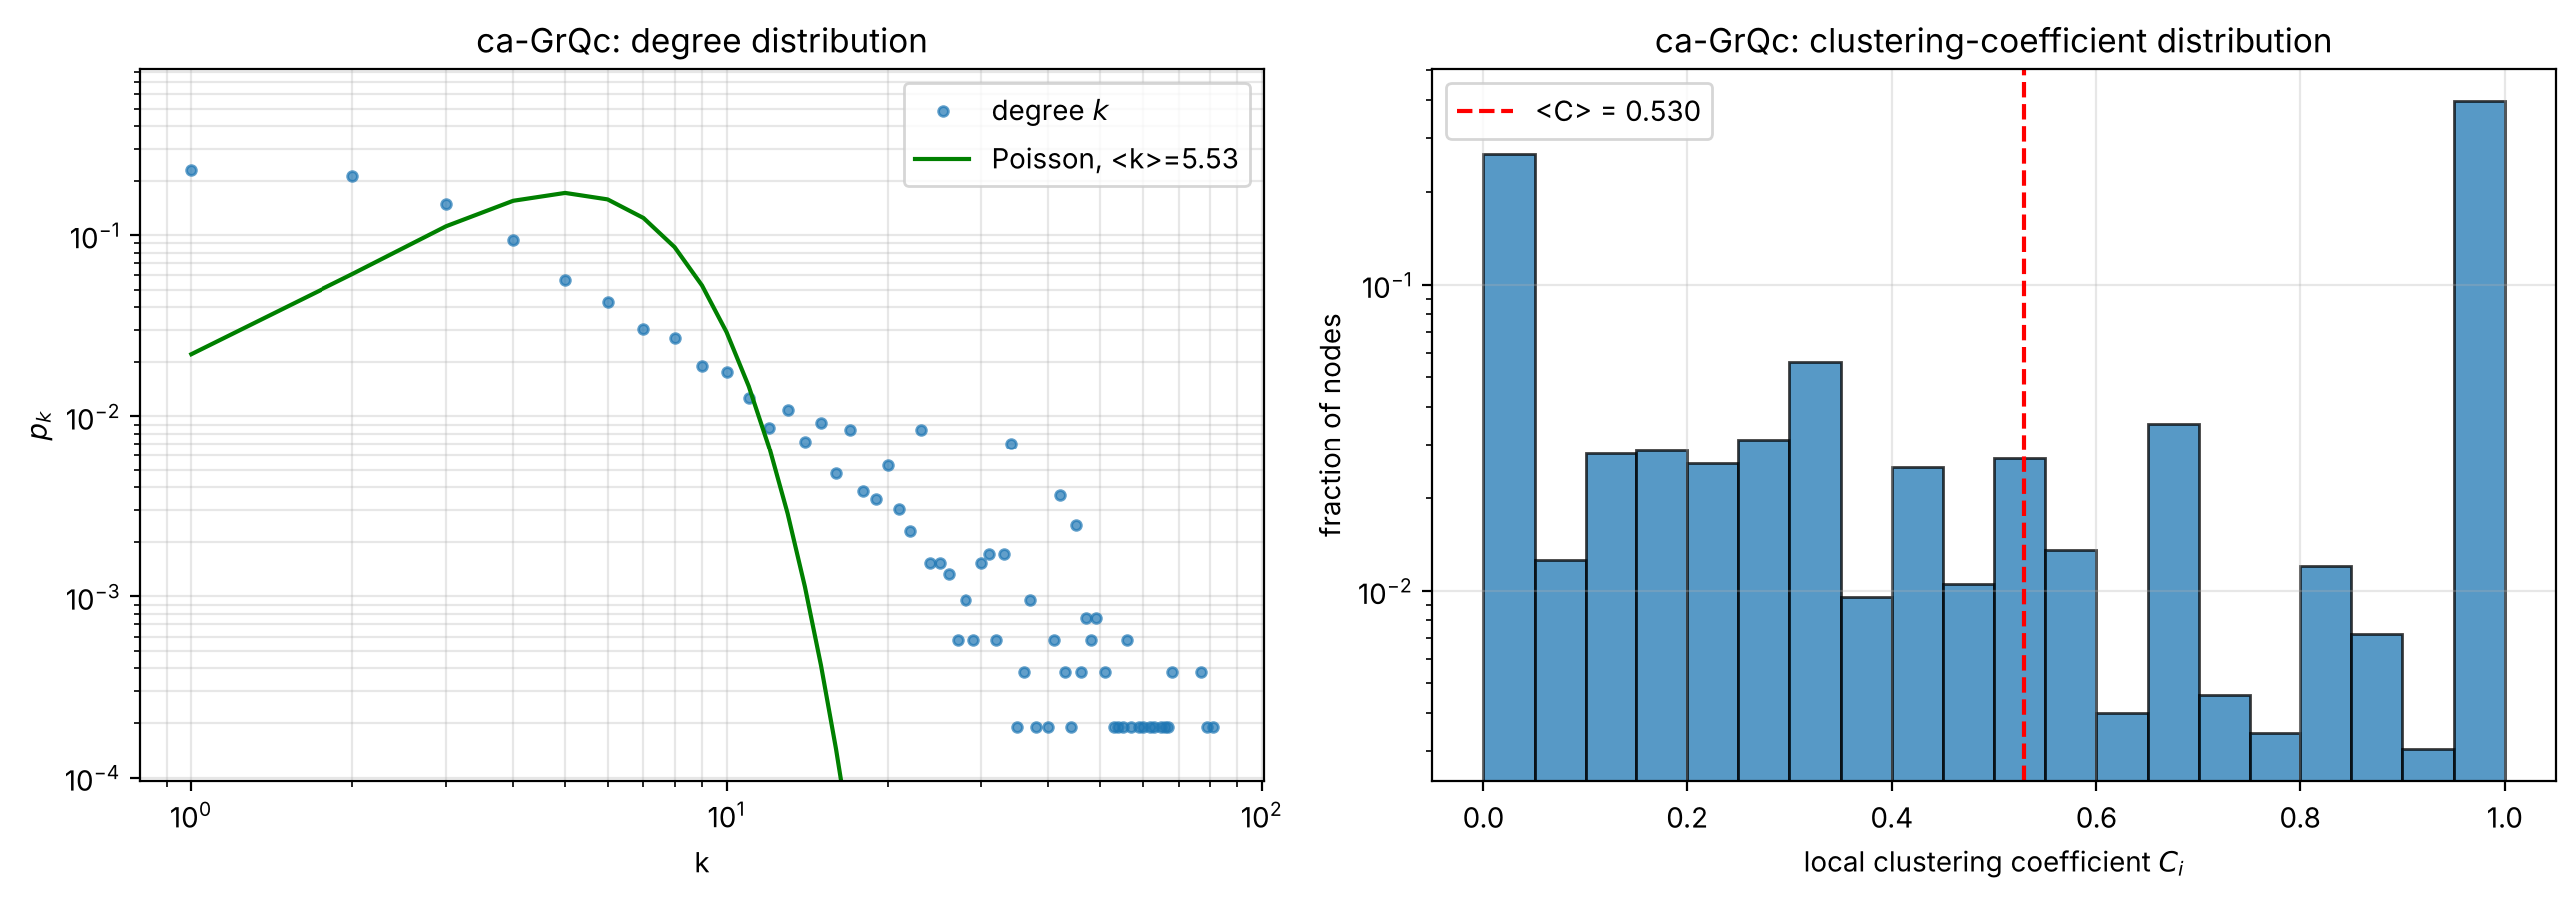

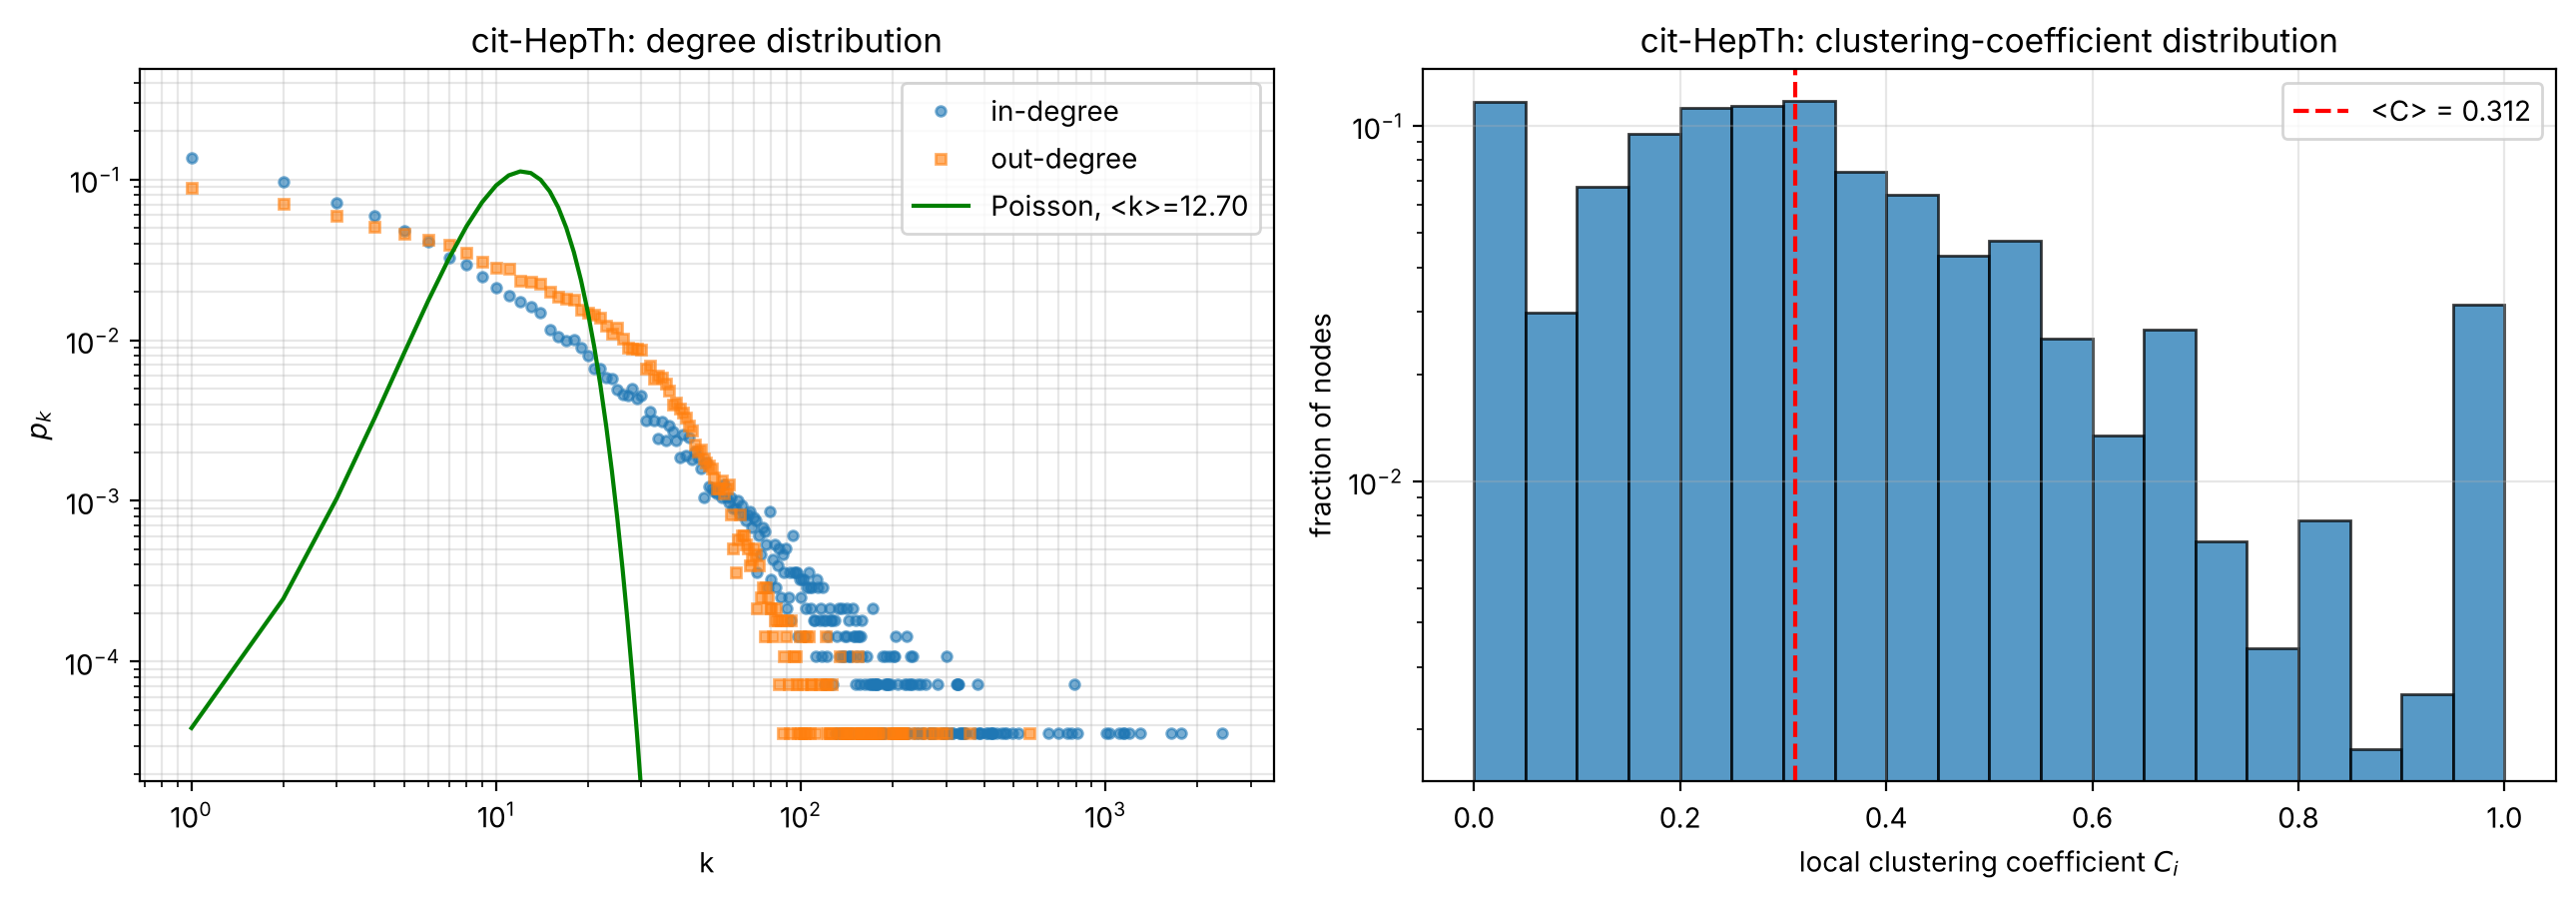

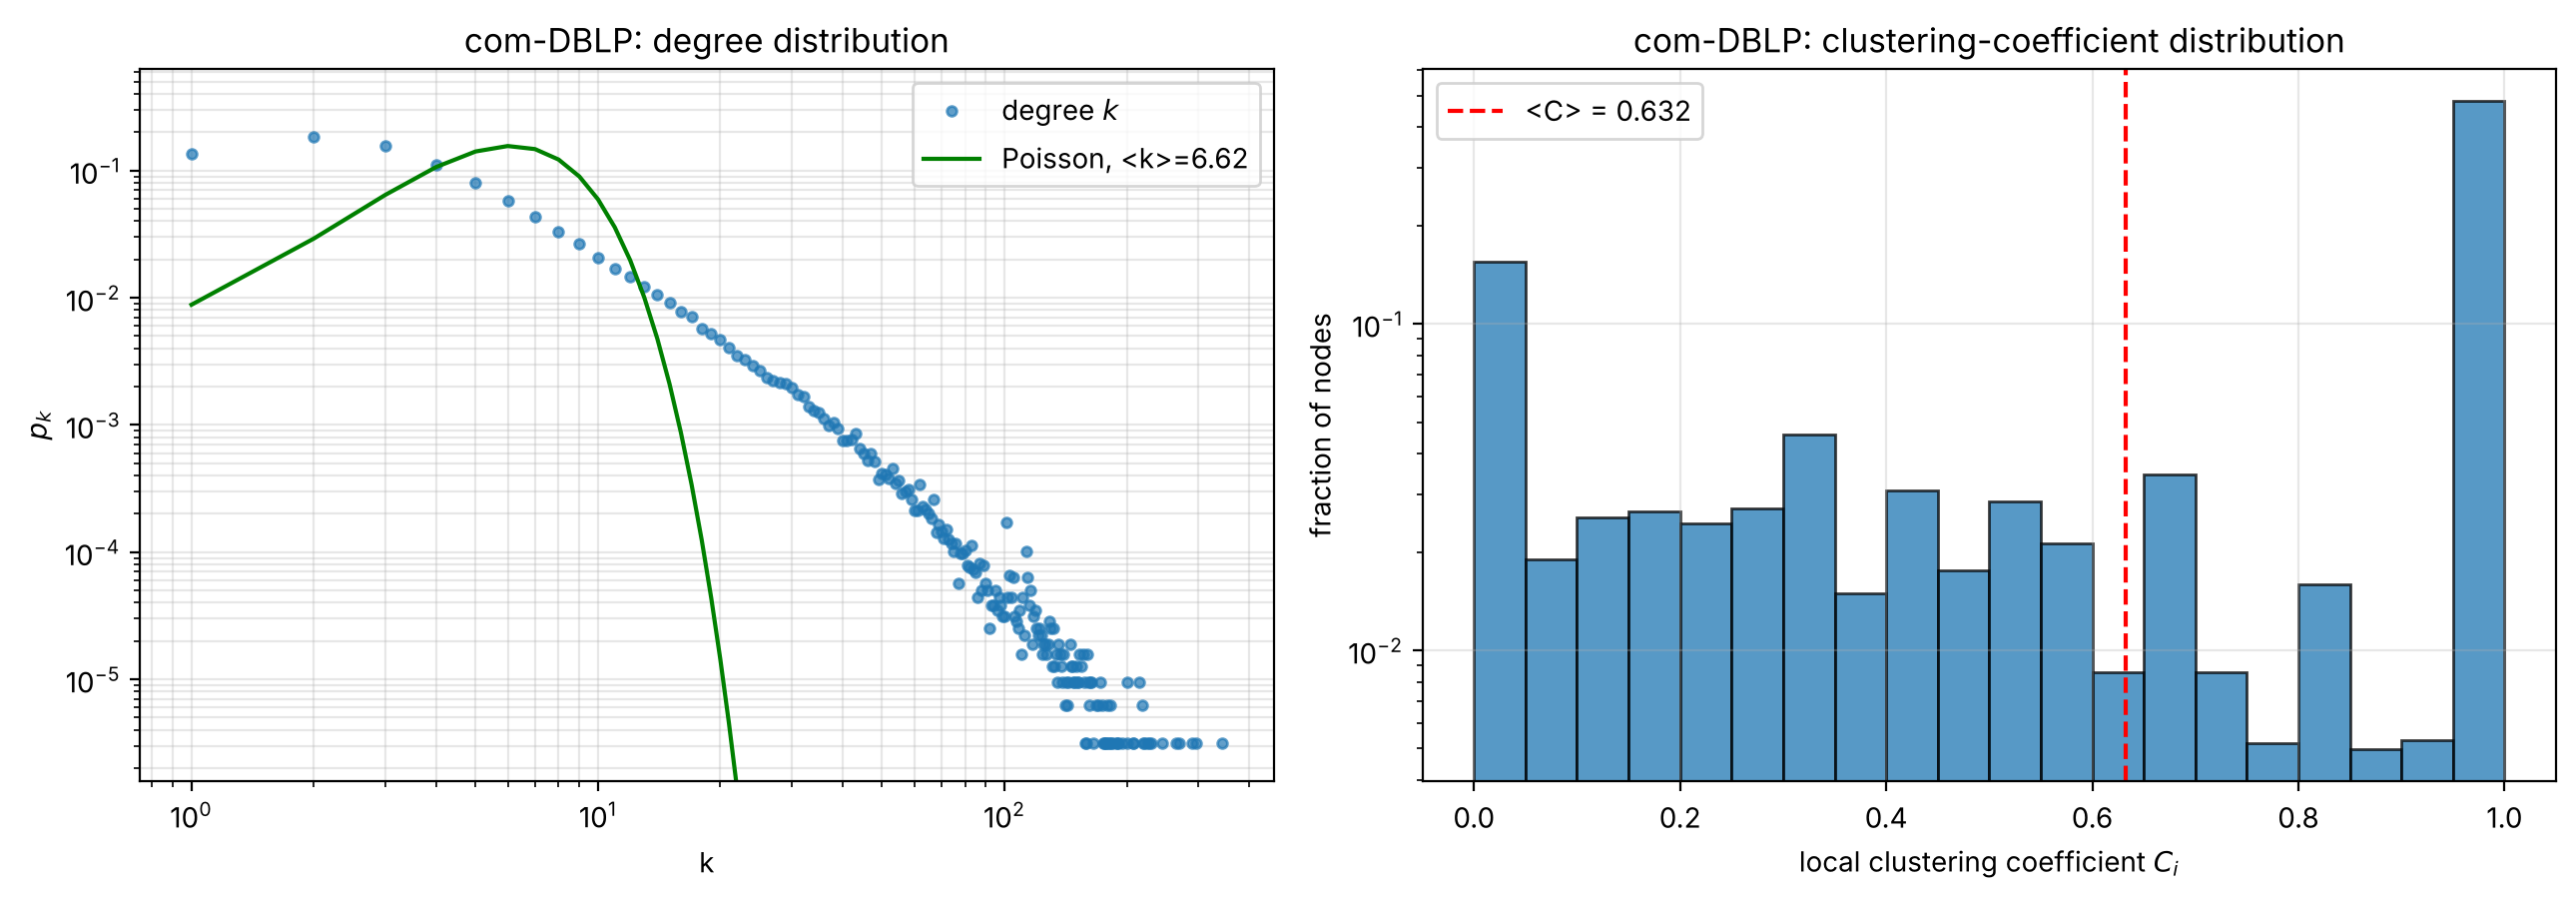

In [6]:
# CELL 6 - Task 2: degree distribution (log-log, with Poisson reference) and clustering-coefficient
# distribution of each real network.
def pk_points(deg):
    ks, cnt = np.unique(np.asarray(deg), return_counts=True)
    pk = cnt / len(deg)
    return ks[ks > 0], pk[ks > 0]

BINS = np.linspace(0, 1, 21)
def clustering_hist(C, empty_as_nan=False):
    h, _ = np.histogram(C, bins=BINS)
    h = h / len(C)
    if empty_as_nan:          # empty bins cannot be drawn on a log axis -> leave a gap
        h[h == 0] = np.nan
    return h

def plot_poisson(ax, k_avg, kmax):
    k = np.arange(1, kmax + 1)
    p = poisson.pmf(k, k_avg)
    ax.plot(k[p > 1e-12], p[p > 1e-12], "g-", lw=1.5, label=f"Poisson, <k>={k_avg:.2f}")

for row in real_rows:
    name, e = row["Dataset"], real_extra[row["Dataset"]]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
    ax = axes[0]
    if "k" in e:
        ks, pk = pk_points(e["k"])
        ax.loglog(ks, pk, "o", ms=3.5, alpha=0.7, label="degree $k$")
        kmax = ks.max()
    else:
        ks, pk = pk_points(e["k_in"]);  ax.loglog(ks, pk, "o", ms=3.5, alpha=0.6, label="in-degree")
        ks2, pk2 = pk_points(e["k_out"]); ax.loglog(ks2, pk2, "s", ms=3.5, alpha=0.6, label="out-degree")
        kmax = max(ks.max(), ks2.max())
    plot_poisson(ax, row["<k>"], kmax)
    ax.set_ylim(bottom=0.5 / row["N (nodes)"])
    ax.set(xlabel="k", ylabel="$p_k$", title=f"{name}: degree distribution")
    ax.legend(); ax.grid(alpha=0.3, which="both")

    ax = axes[1]
    ax.bar(BINS[:-1], clustering_hist(e["C"]), width=0.05, align="edge", edgecolor="k", alpha=0.75)
    ax.axvline(row["<C>"], color="r", ls="--", label=f"<C> = {row['<C>']:.3f}")
    ax.set_yscale("log")
    ax.set(xlabel="local clustering coefficient $C_i$", ylabel="fraction of nodes",
           title=f"{name}: clustering-coefficient distribution")
    ax.legend(); ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(f"{OUT_DIR}/fig_real_{name}.png", dpi=150)
    plt.show()

## 3. Synthetic graphs (N = nodes of the smallest dataset, `ca-GrQc`)
Parameters are chosen so that the number of edges is as close as possible to L of `ca-GrQc`:

| model | networkx function | parameter rule | why L cannot always match exactly |
|---|---|---|---|
| Erdős–Rényi | `fast_gnp_random_graph(N, p)` | p = 2L / (N(N−1)) ⇒ ⟨L⟩ = L | L is random, Binomial(N(N−1)/2, p) (slides 11–12, `03_NetworksModels`) |
| Watts–Strogatz | `watts_strogatz_graph(N, k, β=0.1)` | k = even integer nearest to 2L/N | L = N·k/2 exactly, k must be an even integer |
| Barabási–Albert | `barabasi_albert_graph(N, m)` | m = integer nearest to L/N | L = m(N − m) exactly, m must be an integer |

β = 0.1 places the Watts–Strogatz graphs in the small-world regime (short paths and high clustering at the same time).
`fast_gnp_random_graph` generates exactly the G(N, p) model of the slides; it is only a faster algorithm for sparse graphs.
Each of the 5 graphs uses a different random seed (seeds 1–5), so the results are reproducible.

In [7]:
# CELL 7 - Task 3 setup: N = nodes of the smallest dataset; choose parameters of the three models
# so that the number of edges is close to that of ca-GrQc.
base = graphs["ca-GrQc"]
N0, L0 = base.number_of_nodes(), base.number_of_edges()
p_er = 2 * L0 / (N0 * (N0 - 1))
k_ws = int(2 * round(L0 / N0))          # nearest even integer to 2L/N
beta_ws = 0.1
m_ba = int(round(L0 / N0))
print(f"N = {N0}, target L = {L0}, target <k> = {2*L0/N0:.3f}")
print(f"ER: p = {p_er:.6f}  -> expected L = {p_er * N0 * (N0 - 1) / 2:.0f}, "
      f"theoretical std of L = {math.sqrt(p_er * (1 - p_er) * N0 * (N0 - 1) / 2):.1f}")
print(f"WS: k = {k_ws}, beta = {beta_ws} -> L = N*k/2 = {N0 * k_ws // 2}")
print(f"BA: m = {m_ba}           -> L = m(N-m) = {m_ba * (N0 - m_ba)}")

MODELS = {
    "Erdos-Renyi":     lambda s: nx.fast_gnp_random_graph(N0, p_er, seed=s),
    "Watts-Strogatz":  lambda s: nx.watts_strogatz_graph(N0, k_ws, beta_ws, seed=s),
    "Barabasi-Albert": lambda s: nx.barabasi_albert_graph(N0, m_ba, seed=s),
}
SEEDS = [1, 2, 3, 4, 5]
ABBR = {"Erdos-Renyi": "ER", "Watts-Strogatz": "WS", "Barabasi-Albert": "BA"}

N = 5242, target L = 14484, target <k> = 5.526
ER: p = 0.001054  -> expected L = 14484, theoretical std of L = 120.3
WS: k = 6, beta = 0.1 -> L = N*k/2 = 15726
BA: m = 3           -> L = m(N-m) = 15717


In [8]:
# CELL 8 - Task 3: generate 5 graphs per model (seeds 1-5), build one feature table per model
# with mean/std rows, and report the mean and std of the number of edges.
model_tables, model_extra = {}, {}
for model, make in MODELS.items():
    rows, extras = [], []
    for i, s in enumerate(SEEDS, 1):
        row, extra = graph_properties(make(s), f"{ABBR[model]}-{i}")
        rows.append(row); extras.append(extra)
    df = pd.DataFrame(rows)
    num = df.select_dtypes("number").columns
    mean = df[num].mean(); mean["Dataset"], mean["Type"] = "mean", ""
    std = df[num].std(ddof=1); std["Dataset"], std["Type"] = "std", ""
    df = pd.concat([df, mean.to_frame().T, std.to_frame().T], ignore_index=True)
    model_tables[model], model_extra[model] = df, extras
    df.to_csv(f"{OUT_DIR}/table_{model}.csv", index=False)

for model, df in model_tables.items():
    Ls = df["L (edges)"].iloc[:5].astype(float)
    print(f"\n=== {model} ===")
    print(f"edges: mean = {Ls.mean():.1f}, std = {Ls.std(ddof=1):.2f}, "
          f"difference from ca-GrQc (L={L0}) = {Ls.mean() - L0:+.1f} ({100 * (Ls.mean() - L0) / L0:+.2f}%)")
    display(df.drop(columns=["Type"]).round(4))

ER-1         N=5,242 L=14,508  [exact]  2.5s


ER-2         N=5,242 L=14,560  [exact]  2.2s


ER-3         N=5,242 L=14,384  [exact]  2.6s


ER-4         N=5,242 L=14,468  [exact]  2.2s


ER-5         N=5,242 L=14,421  [exact]  2.2s


WS-1         N=5,242 L=15,726  [exact]  1.9s


... (10 outputs left out)


=== Watts-Strogatz ===
edges: mean = 15726.0, std = 0.00, difference from ca-GrQc (L=14484) = +1242.0 (+8.57%)


,Dataset,N (nodes),L (edges),<k>,Diameter,Radius,<d>,<C>,lnN,lnN/ln<k>,Giant comp. nodes,Giant comp. %
0,WS-1,5242,15726,6.0,14,10,7.958161,0.444577,8.564458,4.779915,5242,100.0
1,WS-2,5242,15726,6.0,13,10,7.813691,0.435437,8.564458,4.779915,5242,100.0
2,WS-3,5242,15726,6.0,14,10,8.034002,0.450553,8.564458,4.779915,5242,100.0
3,WS-4,5242,15726,6.0,14,10,7.986646,0.446027,8.564458,4.779915,5242,100.0
4,WS-5,5242,15726,6.0,14,10,7.897654,0.440185,8.564458,4.779915,5242,100.0
5,mean,5242.0,15726.0,6.0,13.8,10.0,7.938031,0.443356,8.564458,4.779915,5242.0,100.0
6,std,0.0,0.0,0.0,0.447214,0.0,0.085249,0.00577,0.0,0.0,0.0,0.0



=== Barabasi-Albert ===
edges: mean = 15717.0, std = 0.00, difference from ca-GrQc (L=14484) = +1233.0 (+8.51%)


,Dataset,N (nodes),L (edges),<k>,Diameter,Radius,<d>,<C>,lnN,lnN/ln<k>,Giant comp. nodes,Giant comp. %
0,BA-1,5242,15717,5.996566,7,4,4.099737,0.008371,8.564458,4.781443,5242,100.0
1,BA-2,5242,15717,5.996566,7,4,4.070277,0.007982,8.564458,4.781443,5242,100.0
2,BA-3,5242,15717,5.996566,7,4,4.073958,0.008995,8.564458,4.781443,5242,100.0
3,BA-4,5242,15717,5.996566,7,4,4.104292,0.008141,8.564458,4.781443,5242,100.0
4,BA-5,5242,15717,5.996566,7,4,4.066379,0.008836,8.564458,4.781443,5242,100.0
5,mean,5242.0,15717.0,5.996566,7.0,4.0,4.082929,0.008465,8.564458,4.781443,5242.0,100.0
6,std,0.0,0.0,0.0,0.0,0.0,0.017701,0.000437,0.0,0.0,0.0,0.0


### Degree distributions of the 5 graphs of each model
The real network `ca-GrQc` (grey) is drawn as a reference. The black line is the theoretical prediction of each model:
Poisson for Erdős–Rényi; for Barabási–Albert the stationary distribution pₖ = 2m(m+1)/(k(k+1)(k+2)) ∝ k⁻³.
The Watts–Strogatz model has no simple closed form, so its plot has no theory curve.

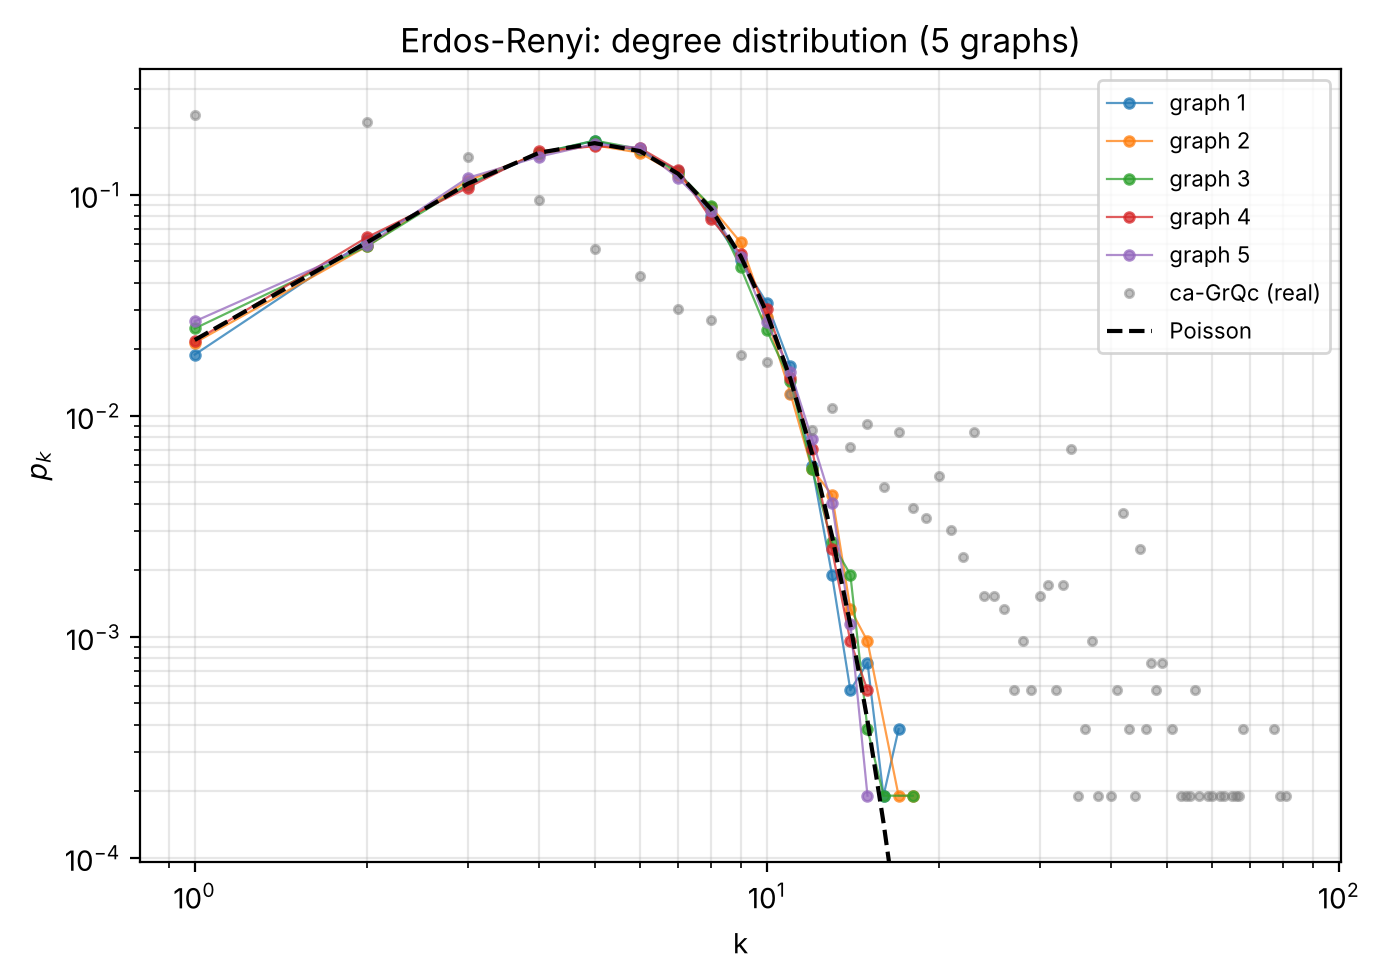

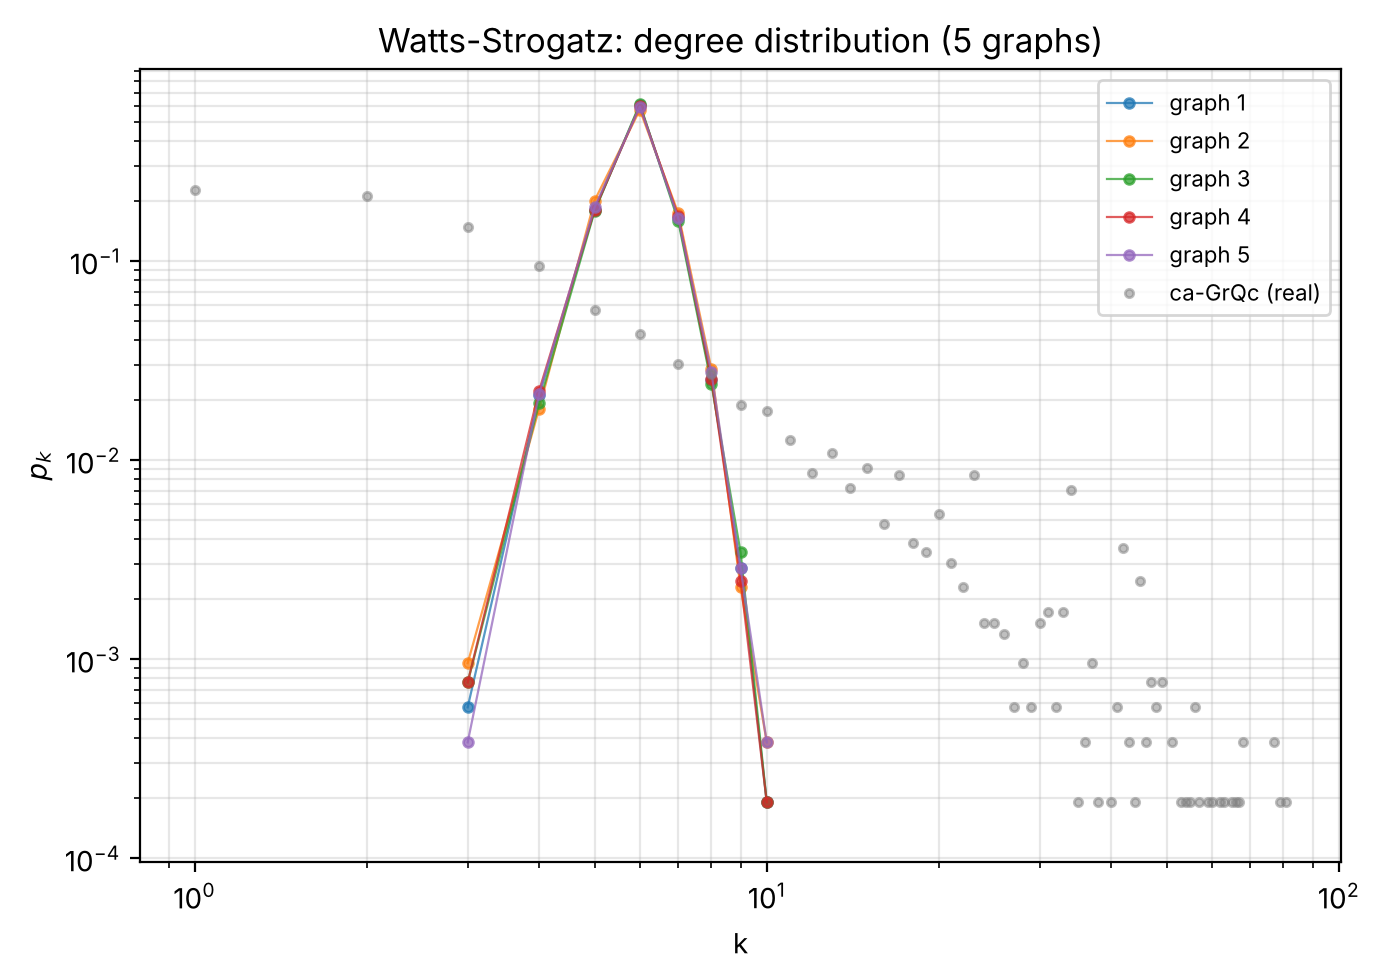

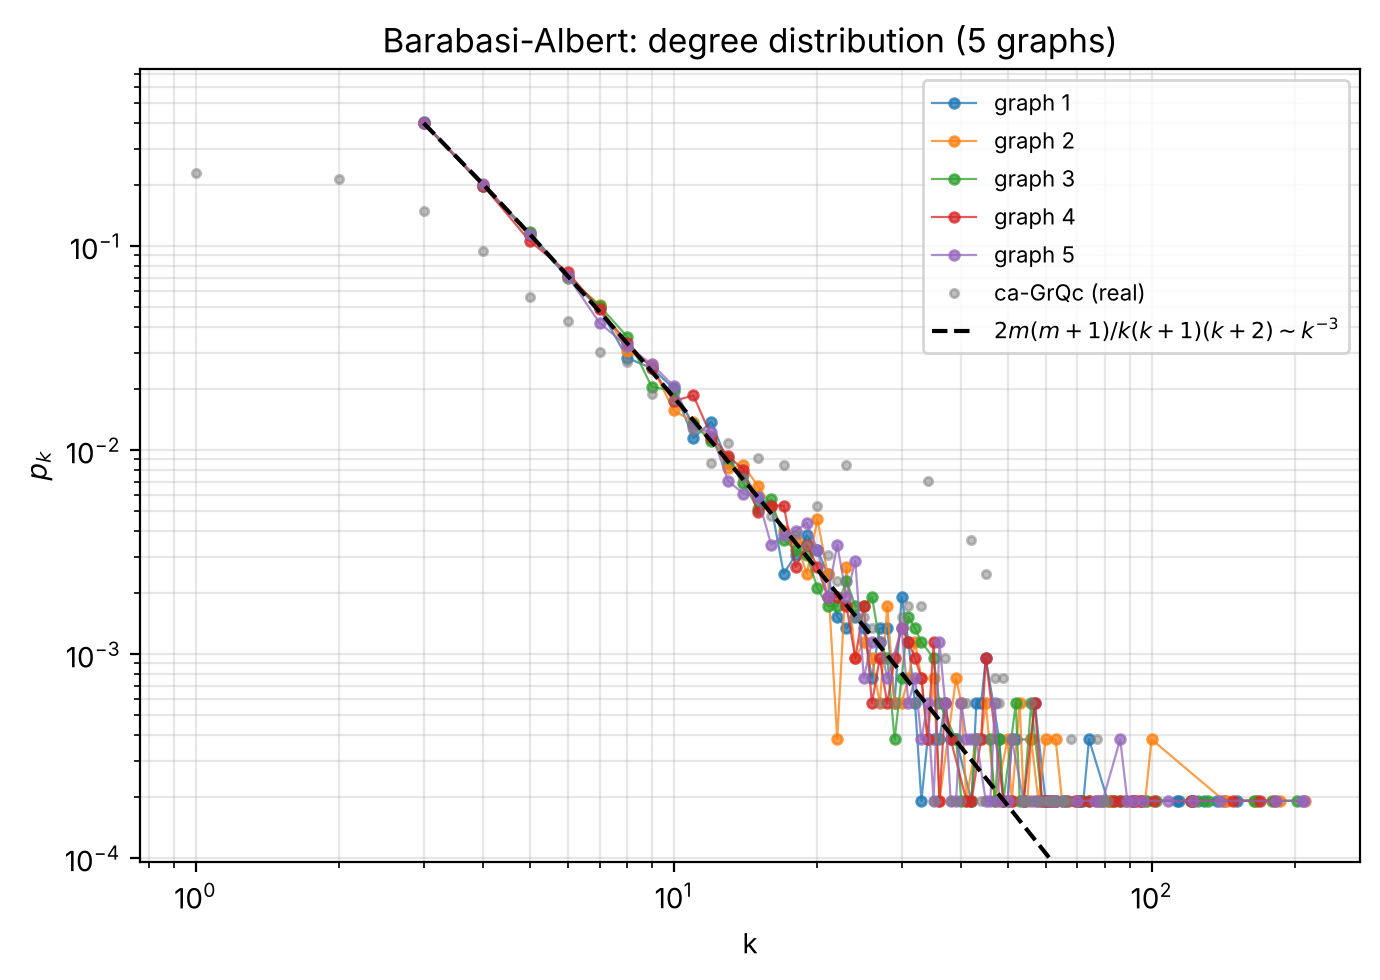

In [9]:
# CELL 9 - Task 3: one degree-distribution plot per model (5 graphs together, real network in grey,
# theory curve for ER and BA).
colors = plt.cm.tab10.colors
base_k = real_extra["ca-GrQc"]["k"]

for model in MODELS:
    fig, ax = plt.subplots(figsize=(7, 5))
    kmax = 0
    for i, e in enumerate(model_extra[model]):
        ks, pk = pk_points(e["k"])
        kmax = max(kmax, ks.max())
        ax.loglog(ks, pk, "o-", ms=3.5, lw=0.8, alpha=0.75, color=colors[i], label=f"graph {i + 1}")
    ks, pk = pk_points(base_k)
    ax.loglog(ks, pk, ".", color="grey", alpha=0.5, label="ca-GrQc (real)")
    if model == "Erdos-Renyi":
        k = np.arange(1, kmax + 1); p = poisson.pmf(k, 2 * L0 / N0)
        ax.loglog(k[p > 1e-12], p[p > 1e-12], "k--", lw=1.5, label="Poisson")
    if model == "Barabasi-Albert":
        k = np.arange(m_ba, kmax + 1)
        ax.loglog(k, 2 * m_ba * (m_ba + 1) / (k * (k + 1) * (k + 2)), "k--", lw=1.5,
                  label=r"$2m(m+1)/k(k+1)(k+2) \sim k^{-3}$")
    ax.set_ylim(bottom=0.5 / N0)
    ax.set(xlabel="k", ylabel="$p_k$", title=f"{model}: degree distribution (5 graphs)")
    ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both")
    fig.tight_layout(); fig.savefig(f"{OUT_DIR}/fig_degree_{model}.png", dpi=150); plt.show()

### Clustering-coefficient distributions of the 5 graphs of each model
Same 20 bins in [0, 1]; the real network `ca-GrQc` (grey) is the reference.

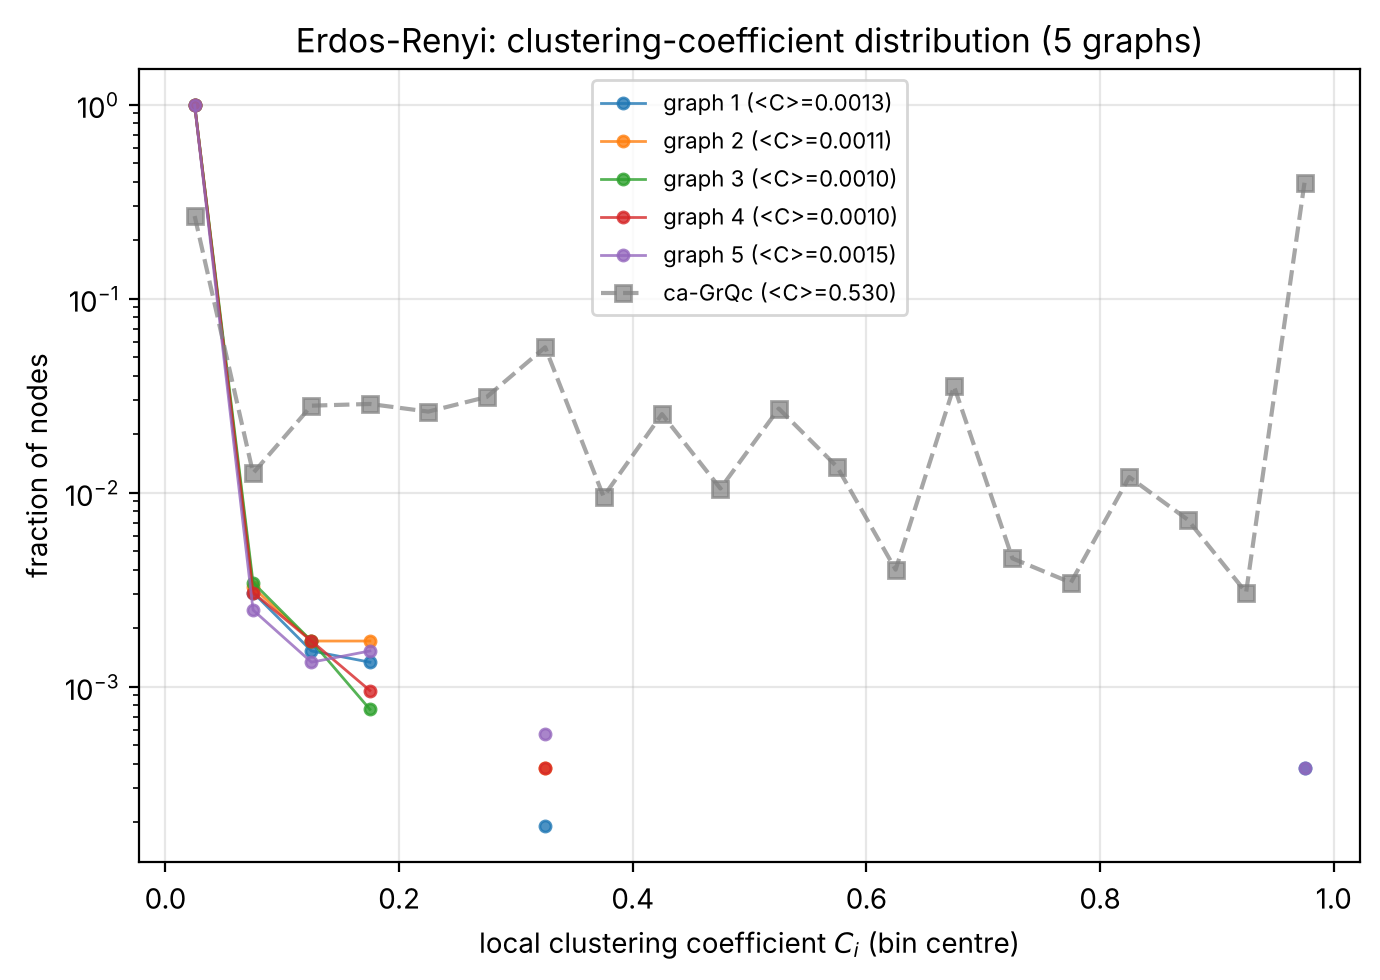

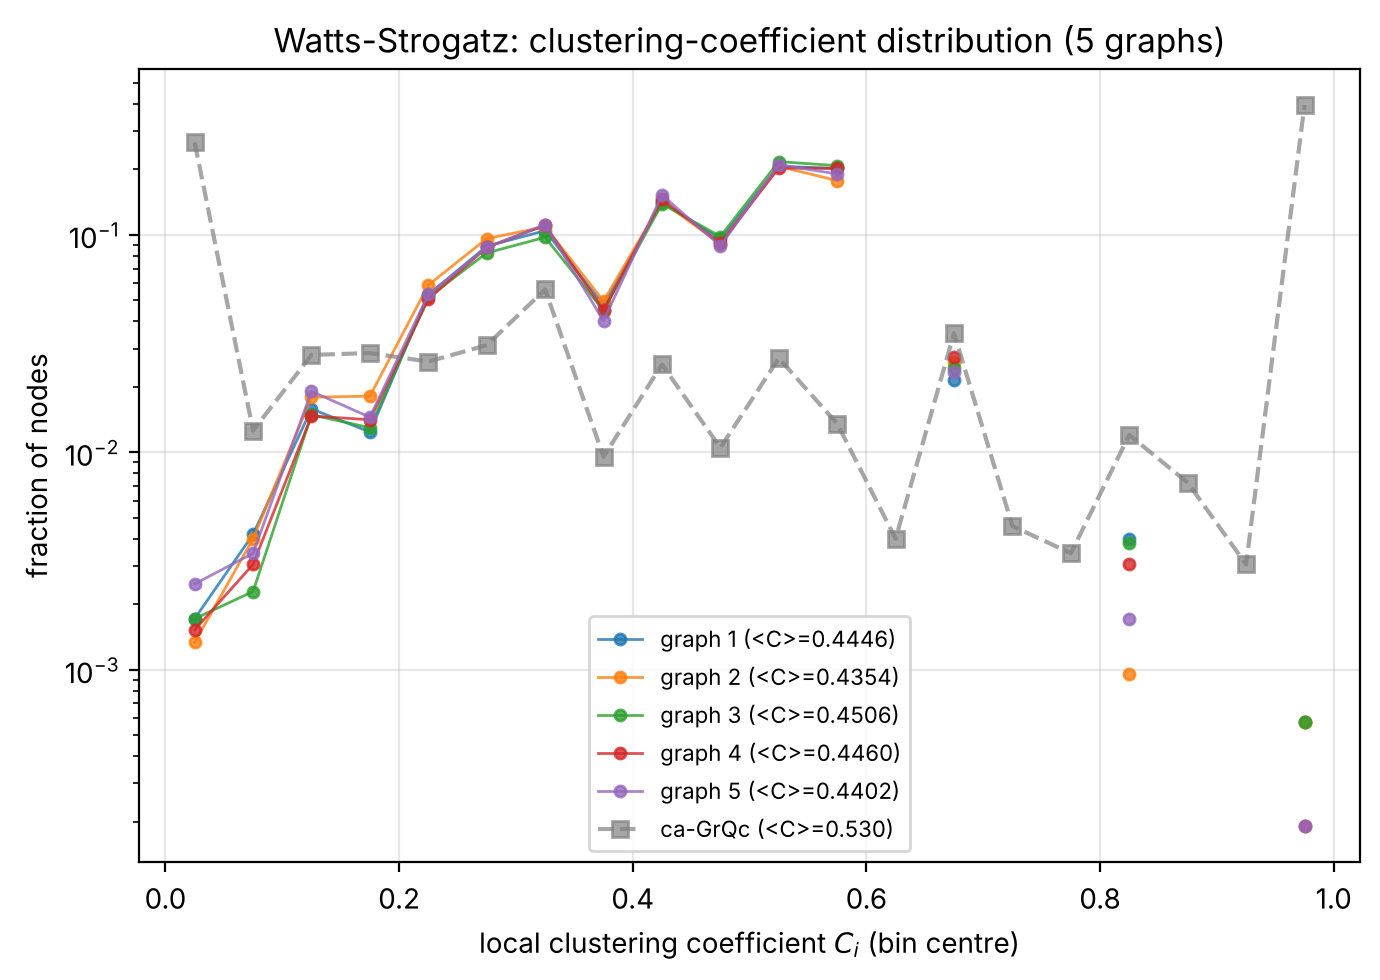

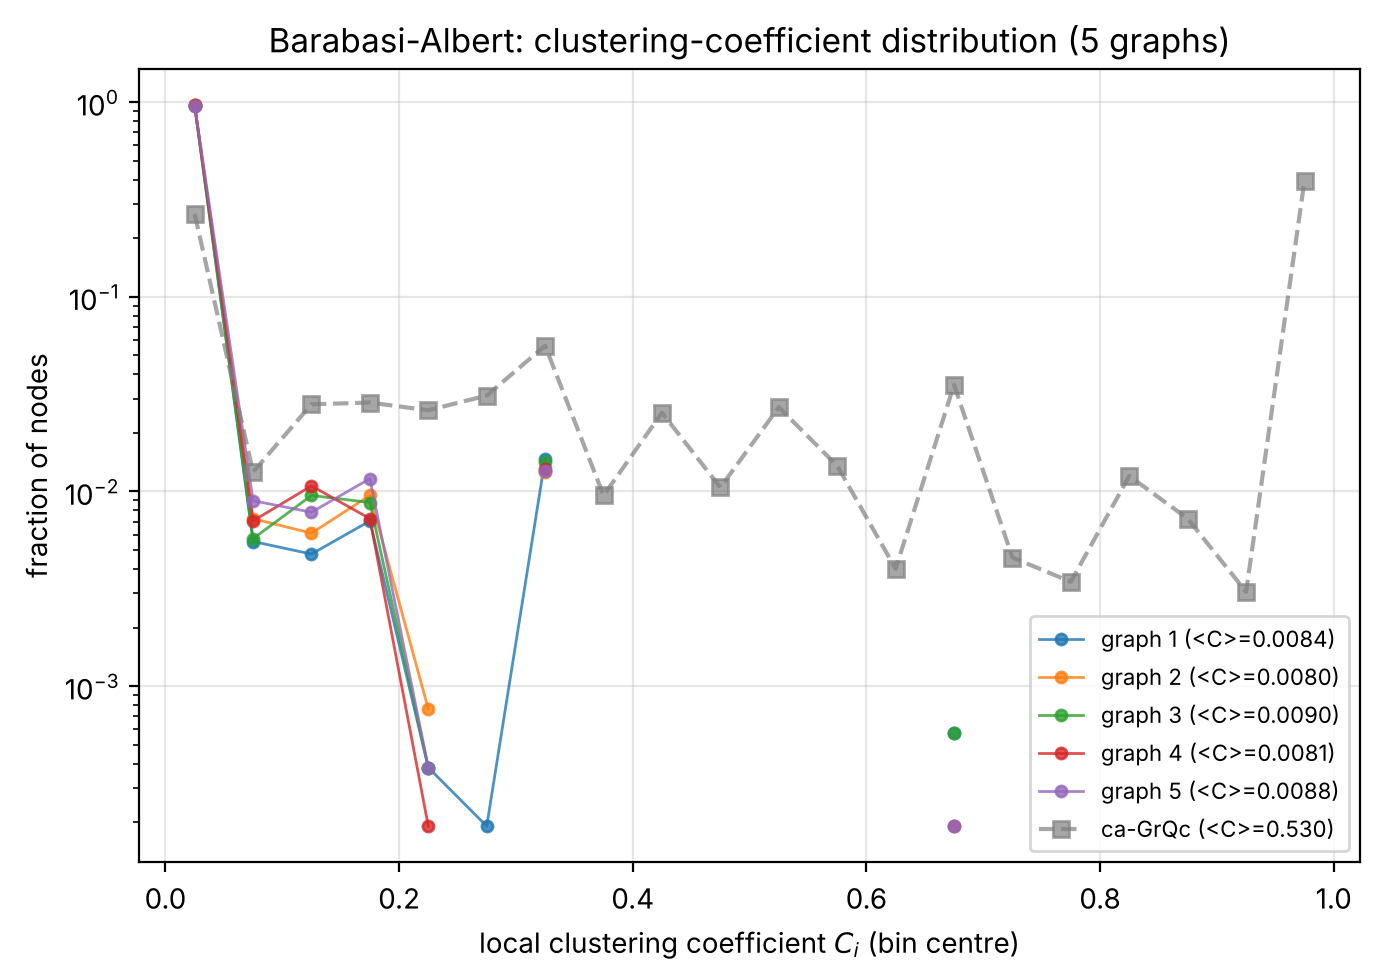

In [10]:
# CELL 10 - Task 3: one clustering-coefficient-distribution plot per model (5 graphs together).
centers = (BINS[:-1] + BINS[1:]) / 2
for model in MODELS:
    fig, ax = plt.subplots(figsize=(7, 5))
    for i, e in enumerate(model_extra[model]):
        ax.plot(centers, clustering_hist(e["C"], True), "o-", ms=4, lw=1, alpha=0.8, color=colors[i],
                label=f"graph {i + 1} (<C>={e['C'].mean():.4f})")
    ax.plot(centers, clustering_hist(real_extra["ca-GrQc"]["C"], True), "s--", color="grey", alpha=0.7,
            label=f"ca-GrQc (<C>={real_extra['ca-GrQc']['C'].mean():.3f})")
    ax.set_yscale("log")
    ax.set(xlabel="local clustering coefficient $C_i$ (bin centre)", ylabel="fraction of nodes",
           title=f"{model}: clustering-coefficient distribution (5 graphs)")
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(f"{OUT_DIR}/fig_clustering_{model}.png", dpi=150); plt.show()

### Summary: real network vs. model means (used in the analysis)
`C_rand = <k>/N` is the random-network prediction for clustering (slide 37, `03_NetworksModels`).

In [11]:
# CELL 11 - Summary table: real network vs. mean of each model (+ random-graph prediction <k>/N for C).
summary = [real_table.iloc[0].drop(["Type"]).to_dict()]
for model, df in model_tables.items():
    r = df.iloc[5].drop(["Type"]).to_dict(); r["Dataset"] = f"{model} (mean of 5)"
    summary.append(r)
summary = pd.DataFrame(summary)
summary["C_rand=<k>/N"] = summary["<k>"] / summary["N (nodes)"]
summary.to_csv(f"{OUT_DIR}/table_summary.csv", index=False)
summary.round(4)

,Dataset,N (nodes),L (edges),<k>,Diameter,Radius,<d>,<C>,lnN,lnN/ln<k>,Giant comp. nodes,Giant comp. %,C_rand=<k>/N
0,ca-GrQc,5242.0,14484.0,5.5261,17.0,9.0,6.0494,0.5296,8.5645,5.0100,4158.0,79.3209,0.0011
1,Erdos-Renyi (mean of 5),5242.0,14468.2,5.5201,10.4,7.0,5.2021,0.0012,8.5645,5.0132,5219.2,99.5651,0.0011
2,Watts-Strogatz (mean of 5),5242.0,15726.0,6.0000,13.8,10.0,7.9380,0.4434,8.5645,4.7799,5242.0,100.0000,0.0011
3,Barabasi-Albert (mean of 5),5242.0,15717.0,5.9966,7.0,4.0,4.0829,0.0085,8.5645,4.7814,5242.0,100.0000,0.0011


In [12]:
# CELL 12 - Zip all tables and figures and download them (Colab only).
import shutil
shutil.make_archive("results", "zip", OUT_DIR)
try:
    from google.colab import files
    files.download("results.zip")
except ImportError:
    print("results.zip created")

results.zip created
